# MNIST ile MLP Tabanlı El Yazısı Rakam Tanıma

**Can Zenginel - 269797015**

Çalıştırma: hücreleri yukarıdan aşağıya sırayla çalıştırın. El yazısı bölümü için `IMG_20261027_153834.jpg` dosyasını Colab'de `/content/` altına yükleyin.

In [1]:
pip install torch torchvision matplotlib pillow

## 1. Veri hazırlama (train / validation / test)

In [2]:
import torch
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

# Tekrarlanabilirlik için sabit seed
SEED = 42
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Cihaz:", device)

# MNIST normalizasyonu (eğitim setinin ortalaması ve standart sapması)
MEAN, STD = 0.1307, 0.3081
transform = transforms.Compose([
    transforms.ToTensor(),                 # [0,255] -> [0,1], şekil: 1x28x28
    transforms.Normalize((MEAN,), (STD,))  # normalizasyon
])

# 60.000 eğitim + 10.000 test görüntüsü
full_train = datasets.MNIST("./data", train=True,  download=True, transform=transform)
test_set   = datasets.MNIST("./data", train=False, download=True, transform=transform)

# Eğitim setini train (54.000) ve validation (6.000) olarak ayır
train_set, val_set = random_split(
    full_train, [54000, 6000],
    generator=torch.Generator().manual_seed(SEED)
)

BATCH_SIZE = 64
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_set,   batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(test_set,  batch_size=BATCH_SIZE, shuffle=False)

print(f"Train: {len(train_set)} | Validation: {len(val_set)} | Test: {len(test_set)}")

Cihaz: cpu


100%|██████████| 9.91M/9.91M [00:00<00:00, 36.4MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.10MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 10.8MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.16MB/s]

Train: 54000 | Validation: 6000 | Test: 10000


## 2. Deney 1: Temel MLP (eğitim)

In [3]:
import torch.nn as nn
import torch.optim as optim
import time

# ---------- Hiperparametreler (raporda belirtilecek) ----------
HIDDEN1 = 256
HIDDEN2 = 128
LR = 0.001
EPOCHS = 15
# BATCH_SIZE = 64 (Adım 1'de tanımlandı), Optimizer: Adam

# ---------- Model ----------
class MLP(nn.Module):
    def __init__(self, h1, h2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),             # 1x28x28 -> 784
            nn.Linear(784, h1),
            nn.ReLU(),
            nn.Linear(h1, h2),
            nn.ReLU(),
            nn.Linear(h2, 10)         # 10 sınıf, softmax loss içinde
        )

    def forward(self, x):
        return self.net(x)

model = MLP(HIDDEN1, HIDDEN2).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LR)
print(model)

# ---------- Yardımcı: bir veri kümesi üzerinde loss ve accuracy ----------
def evaluate(model, loader):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            total_loss += criterion(out, y).item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            total += x.size(0)
    return total_loss / total, correct / total

# ---------- Eğitim döngüsü ----------
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

start = time.time()
for epoch in range(EPOCHS):
    model.train()
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        loss = criterion(model(x), y)
        loss.backward()
        optimizer.step()

    # Her epoch sonunda train ve validation ölçümü
    tr_loss, tr_acc = evaluate(model, train_loader)
    va_loss, va_acc = evaluate(model, val_loader)
    history["train_loss"].append(tr_loss)
    history["val_loss"].append(va_loss)
    history["train_acc"].append(tr_acc)
    history["val_acc"].append(va_acc)

    print(f"Epoch {epoch+1:2d}/{EPOCHS} | "
          f"train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
          f"val loss {va_loss:.4f} acc {va_acc:.4f}")

train_time = time.time() - start
print(f"\nEğitim süresi: {train_time:.1f} saniye")

MLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)
Epoch  1/15 | train loss 0.1054 acc 0.9685 | val loss 0.1382 acc 0.9585
Epoch  2/15 | train loss 0.0634 acc 0.9801 | val loss 0.0960 acc 0.9710
Epoch  3/15 | train loss 0.0468 acc 0.9859 | val loss 0.0901 acc 0.9725
Epoch  4/15 | train loss 0.0360 acc 0.9886 | val loss 0.0799 acc 0.9760
Epoch  5/15 | train loss 0.0260 acc 0.9920 | val loss 0.0796 acc 0.9757
Epoch  6/15 | train loss 0.0259 acc 0.9912 | val loss 0.0966 acc 0.9728
Epoch  7/15 | train loss 0.0273 acc 0.9910 | val loss 0.0888 acc 0.9735
Epoch  8/15 | train loss 0.0221 acc 0.9921 | val loss 0.0969 acc 0.9773
Epoch  9/15 | train loss 0.0222 acc 0.9926 | val loss 0.1030 acc 0.9772
Epoch 10/15 | train loss 0.0164 acc 0.9940 | val loss 0.1177 

## 3. Loss/accuracy grafikleri ve test sonucu

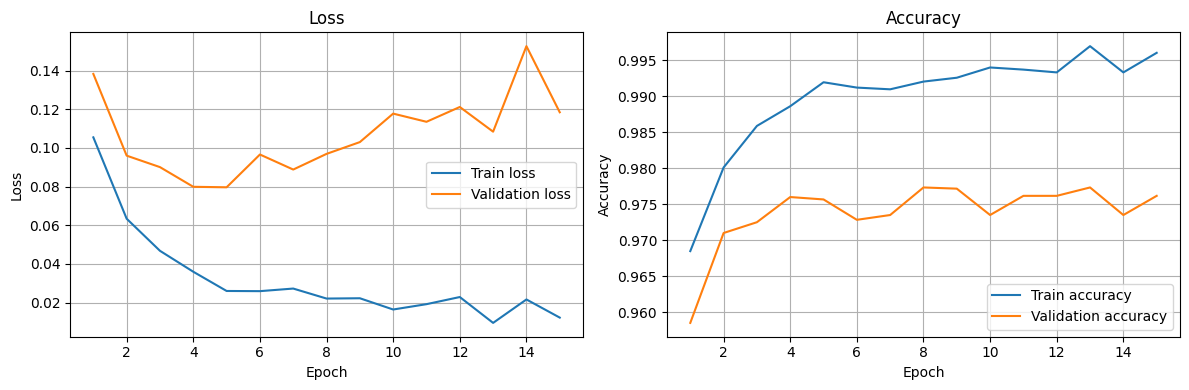

Test loss: 0.1169 | Test accuracy: 0.9784


In [4]:
import matplotlib.pyplot as plt

epochs_range = range(1, EPOCHS + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Loss grafiği
axes[0].plot(epochs_range, history["train_loss"], label="Train loss")
axes[0].plot(epochs_range, history["val_loss"], label="Validation loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title("Loss")
axes[0].legend()
axes[0].grid(True)

# Accuracy grafiği
axes[1].plot(epochs_range, history["train_acc"], label="Train accuracy")
axes[1].plot(epochs_range, history["val_acc"], label="Validation accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_title("Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig("deney1_egriler.png", dpi=150)   # README'de kullanacağız
plt.show()

# ---------- Test accuracy: SADECE BİR KEZ, en sonda ----------
test_loss, test_acc = evaluate(model, test_loader)
print(f"Test loss: {test_loss:.4f} | Test accuracy: {test_acc:.4f}")

# Modeli kaydet (Adım 4'te el yazısı için lazım olacak)
torch.save(model.state_dict(), "mlp_deney1.pt")

## 4. Kendi el yazım (okul numarası) ile test

Bulunan rakam sayısı: 18 (beklenen: 18)
Üst satır: 9 | Alt satır: 9

El yazısı accuracy: 16/18 = 88.89%
Üst satır: 8/9
Alt satır: 8/9


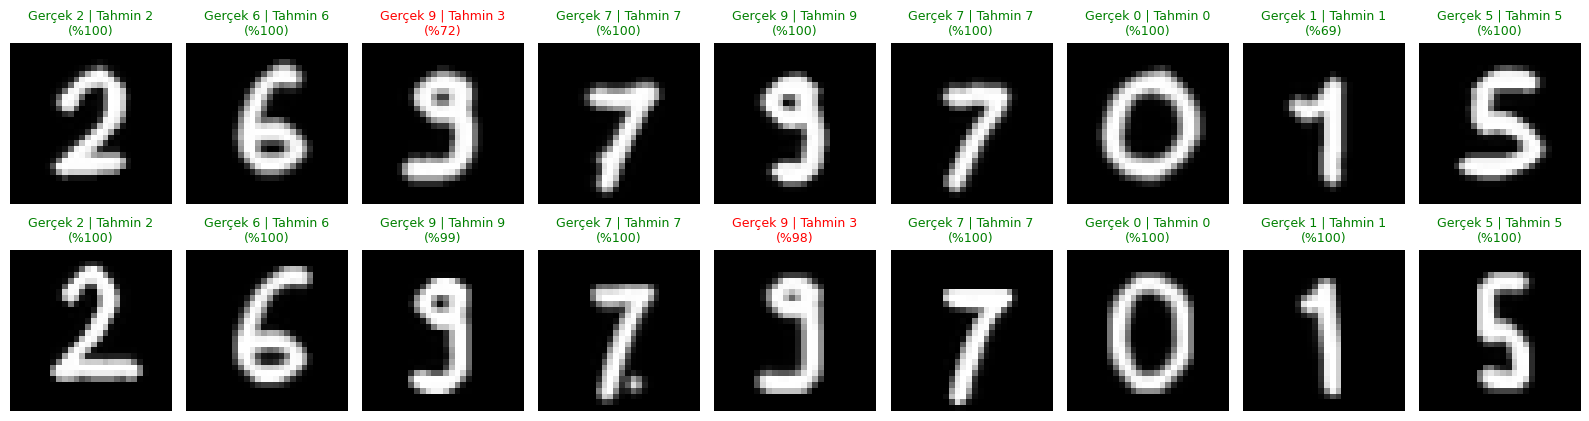

In [5]:
import os
import numpy as np
from PIL import Image
from scipy import ndimage
import matplotlib.pyplot as plt

IMG_PATH = "/content/IMG_20261027_153834.jpg"
LABELS = "269797015"
os.makedirs("el_yazisi", exist_ok=True)

gray = np.array(Image.open(IMG_PATH).convert("L")).astype(np.float32)

bg = ndimage.maximum_filter(gray, size=25)
bg = ndimage.gaussian_filter(bg, sigma=10)
mask = (bg - gray) > 40

merged = ndimage.binary_dilation(mask, iterations=6)
lab, n = ndimage.label(merged)
H, W = gray.shape
boxes = []
for sl in ndimage.find_objects(lab):
    h = sl[0].stop - sl[0].start
    w = sl[1].stop - sl[1].start
    ink = mask[sl].sum()
    on_border = sl[0].start == 0 or sl[1].start == 0 or sl[0].stop == H or sl[1].stop == W
    if h > 20 and ink > 40 and not on_border:
        boxes.append(sl)
print("Bulunan rakam sayısı:", len(boxes), "(beklenen: 18)")

cy = [(s[0].start + s[0].stop) / 2 for s in boxes]
split = (min(cy) + max(cy)) / 2
row1 = sorted([b for b, c in zip(boxes, cy) if c < split], key=lambda s: s[1].start)
row2 = sorted([b for b, c in zip(boxes, cy) if c >= split], key=lambda s: s[1].start)
print("Üst satır:", len(row1), "| Alt satır:", len(row2))

def to_mnist(sl):
    digit = mask[sl].astype(np.float32)
    h, w = digit.shape
    t = max(1, int(round(max(h, w) * 0.07)))
    digit = ndimage.binary_dilation(digit > 0, iterations=t).astype(np.float32) * 255
    scale = 20.0 / max(h, w)
    new_w = max(1, int(round(w * scale)))
    new_h = max(1, int(round(h * scale)))
    small = Image.fromarray(digit.astype(np.uint8)).resize((new_w, new_h), Image.LANCZOS)
    canvas = np.zeros((28, 28), dtype=np.float32)
    y0 = (28 - new_h) // 2
    x0 = (28 - new_w) // 2
    canvas[y0:y0 + new_h, x0:x0 + new_w] = np.array(small)
    cy_, cx_ = ndimage.center_of_mass(canvas)
    canvas = ndimage.shift(canvas, (14 - cy_, 14 - cx_), order=1)
    return np.clip(canvas, 0, 255) / 255.0

all_boxes = row1 + row2
imgs = np.stack([to_mnist(b) for b in all_boxes])
true_labels = [int(c) for c in LABELS] * 2

for i, im in enumerate(imgs):
    Image.fromarray((im * 255).astype(np.uint8)).save(f"el_yazisi/rakam_{i:02d}.png")

x = torch.tensor(imgs, dtype=torch.float32).unsqueeze(1)
x = (x - MEAN) / STD
model.eval()
with torch.no_grad():
    probs = torch.softmax(model(x.to(device)), dim=1).cpu()
preds = probs.argmax(1).tolist()
conf = probs.max(1).values.tolist()

correct = sum(p == t for p, t in zip(preds, true_labels))
print(f"\nEl yazısı accuracy: {correct}/{len(preds)} = {correct/len(preds):.2%}")
n1 = len(row1)
ok1 = sum(preds[i] == true_labels[i] for i in range(0, n1))
ok2 = sum(preds[i] == true_labels[i] for i in range(n1, len(preds)))
print(f"Üst satır: {ok1}/{n1}")
print(f"Alt satır: {ok2}/{len(preds) - n1}")

fig, axes = plt.subplots(2, 9, figsize=(16, 4.5))
for i, ax in enumerate(axes.flat):
    if i >= len(imgs):
        ax.axis("off")
        continue
    ax.imshow(imgs[i], cmap="gray")
    color = "green" if preds[i] == true_labels[i] else "red"
    ax.set_title(f"Gerçek {true_labels[i]} | Tahmin {preds[i]}\n(%{conf[i]*100:.0f})", color=color, fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.savefig("el_yazisi_sonuc.png", dpi=150)
plt.show()